# Uncertainty Types in Deep Learning

**Module 06 · AI Safety (ISO/PAS 8800)** · Notebook 2 of 7

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/06_AI_Safety_ISO_PAS_8800/02_uncertainty_types.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Intermediate | [01 AI safety standards](01_ai_safety_standards.ipynb); basic probability; PyTorch basics | ISO 21448:2022, ISO/PAS 8800:2024 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

- Distinguish **aleatoric** (data) and **epistemic** (model/knowledge) uncertainty, and know their limits as concepts.
- Use the two standard decompositions consistently:
  - classification: *total predictive entropy = expected entropy (aleatoric) + mutual information (epistemic)*;
  - regression: *total variance = mean predicted variance (aleatoric) + variance of the predicted means (epistemic)* (law of total variance).
- Compute both decompositions from an ensemble on a toy problem with a data gap.
- Identify sources of uncertainty in AV perception and connect them to ISO 21448 and ISO/PAS 8800.
- Sketch an uncertainty-aware decision rule and explain why its thresholds must be validated.

## Introduction

Imagine an AV perception system detecting a pedestrian with a score of 0.95. Should the vehicle brake?
- If the model is **well calibrated**, about 95 % of detections with this score are real pedestrians.
- If it is **overconfident**, the true rate may be much lower; the score alone does not tell us.
- If the model has **high epistemic uncertainty** for this input (it has not seen anything similar), the score may be unreliable even if the model is calibrated on average.

**Where uncertainty sits in the standards:**
- **ISO 26262** addresses malfunctions of E/E systems. Insufficiencies of specification or performance, which is where ML uncertainty belongs, are addressed by **ISO 21448** and, for AI elements, by **ISO/PAS 8800**.
- ISO/PAS 8800 lists uncertainty-related properties among the safety-related properties of an AI system and discusses uncertainty estimates as input to runtime monitoring (see [01](01_ai_safety_standards.ipynb)).

Uncertainty quantification can help to:
1. flag inputs that are unlike the training data (one input to OOD monitoring),
2. trigger fallback behaviour or a minimal risk manoeuvre,
3. reveal model limitations during development (functional insufficiencies),
4. provide *one* strand of evidence in a safety argument, provided its own quality (calibration, detection performance) is shown.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import torch
import torch.nn as nn
import torch.nn.functional as F

rng = np.random.default_rng(42)
torch.manual_seed(42)
torch.set_num_threads(1)              # tiny models: one thread is fastest and reproducible
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
OI = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#000000"]
print("torch", torch.__version__)

torch 2.15.0+cpu


## 1. Types of uncertainty

### 1.1 Aleatoric uncertainty (data uncertainty)

**Definition:** variability in the outcome that remains even if the model were perfectly known, *given the chosen input representation*.

**Characteristics:**
- Cannot be reduced by more samples of the same inputs. It *can* be reduced by better sensors or features that change the input representation (e.g. adding LiDAR to a camera).
- Arises from noise and ambiguity in observations and labels.
- Also called "statistical" or "data" uncertainty.

**Sources in AV perception:**
- **Sensor noise:** camera photon noise, LiDAR range noise
- **Environmental conditions:** rain drops, fog, glare
- **Motion blur:** fast-moving objects
- **Occlusion and truncation:** partially visible pedestrians
- **Label noise:** inconsistent human annotations

**Two forms:**
- **Homoscedastic:** constant across inputs.
- **Heteroscedastic:** input-dependent (e.g. larger for distant objects).

### 1.2 Epistemic uncertainty (model or knowledge uncertainty)

**Definition:** uncertainty about the model itself, caused by limited data and knowledge.

**Characteristics:**
- Reducible, in principle, with more relevant data.
- Large where training data are sparse or absent.
- Also called "model" or "knowledge" uncertainty.

**Sources in AV perception:**
- **Insufficient training data:** rare scenarios not well represented
- **Out-of-distribution inputs:** novel objects or conditions
- **Domain shift:** trained in sunny weather, deployed in snow
- **Model misspecification** (limited capacity, wrong hypothesis class) is often treated separately from parameter (epistemic) uncertainty, because averaging over the parameters of a wrong model class does not reveal it.

**Key point for safety:** high epistemic uncertainty indicates "little relevant training experience here", which links directly to the *unknown* scenario areas of ISO 21448. It is not a guarantee: ML models can be confidently wrong far from the data (see [03](03_mc_dropout_and_deep_ensembles.ipynb)).

### 1.3 The two decompositions

Let $p(y\mid x,\theta)$ be the predictive distribution of one model with parameters $\theta$ and $q(\theta)$ an (approximate) posterior over parameters, represented by $S$ samples (MC-dropout masks or ensemble members).

**Classification (entropy decomposition)**, e.g. Depeweg et al. (2018):

$$\underbrace{\mathcal H\big[\mathbb E_{q(\theta)}\,p(y\mid x,\theta)\big]}_{\text{total: predictive entropy}}
= \underbrace{\mathbb E_{q(\theta)}\,\mathcal H\big[p(y\mid x,\theta)\big]}_{\text{aleatoric: expected entropy}}
+ \underbrace{\mathcal I\big[y;\theta\mid x\big]}_{\text{epistemic: mutual information}}$$

**Regression (law of total variance)**, e.g. Kendall & Gal (2017), Lakshminarayanan et al. (2017):

$$\underbrace{\operatorname{Var}[y\mid x]}_{\text{total}} = \underbrace{\mathbb E_{q(\theta)}\big[\sigma^2_\theta(x)\big]}_{\text{aleatoric}} + \underbrace{\operatorname{Var}_{q(\theta)}\big[\mu_\theta(x)\big]}_{\text{epistemic}}$$

**Variances add, standard deviations do not**: $\sigma_\text{tot} = \sqrt{\sigma_\text{ale}^2 + \sigma_\text{epi}^2}$, not $\sigma_\text{ale} + \sigma_\text{epi}$. Entropies add as written above.

Both decompositions are model-based estimates. They are only as good as the approximate posterior and the likelihood model; the aleatoric part requires a likelihood that can represent data noise (softmax probabilities, or a predicted variance in regression).

In [2]:
def entropy(p, axis=-1):
    """Shannon entropy in nats."""
    p = np.clip(p, 1e-12, 1.0)
    return -(p * np.log(p)).sum(axis=axis)

def decompose_classification(P):
    """P: array (S, N, C) of class probabilities from S posterior samples.
    Returns total, aleatoric (expected entropy), epistemic (mutual information), each shape (N,)."""
    total = entropy(P.mean(axis=0))
    aleatoric = entropy(P).mean(axis=0)
    return total, aleatoric, np.clip(total - aleatoric, 0, None)   # MI >= 0 (clip rounding error)

def decompose_regression(mu, var):
    """mu, var: arrays (S, N) of predicted means and variances. Law of total variance."""
    aleatoric = var.mean(axis=0)
    epistemic = mu.var(axis=0)
    return aleatoric + epistemic, aleatoric, epistemic

# Three textbook cases with S = 5 ensemble members, binary pedestrian / background
cases = {
    "members agree, confident":   [[0.98, 0.02]] * 5,
    "members agree, ambiguous":   [[0.52, 0.48], [0.50, 0.50], [0.49, 0.51], [0.51, 0.49], [0.50, 0.50]],
    "members disagree, confident": [[0.98, 0.02], [0.03, 0.97], [0.96, 0.04], [0.02, 0.98], [0.97, 0.03]],
}
print(f"{'case':30s} {'total':>7s} {'aleatoric':>10s} {'epistemic (MI)':>15s}   (nats; max for 2 classes = ln 2 = {np.log(2):.3f})")
for name, probs in cases.items():
    P = np.array(probs, dtype=float)[:, None, :]
    t, a, e = (v[0] for v in decompose_classification(P))
    print(f"{name:30s} {t:7.3f} {a:10.3f} {e:15.3f}")

case                             total  aleatoric  epistemic (MI)   (nats; max for 2 classes = ln 2 = 0.693)
members agree, confident         0.098      0.098           0.000
members agree, ambiguous         0.693      0.693           0.000
members disagree, confident      0.676      0.127           0.549


Both the "ambiguous" and the "disagree" cases have a mean prediction close to 50/50, so their **total** uncertainty is nearly the same. Only the decomposition shows that the first is aleatoric (every member says "could be either") and the second is epistemic (every member is sure, but they contradict each other).

## 2. Visualising both types on a 1-D regression problem with a gap

The training inputs cover $[-4,-1]\cup[1,4]$; the gap $(-1,1)$ and the outside $|x|>4$ have no data. The noise is heteroscedastic: it grows with $|x|$.

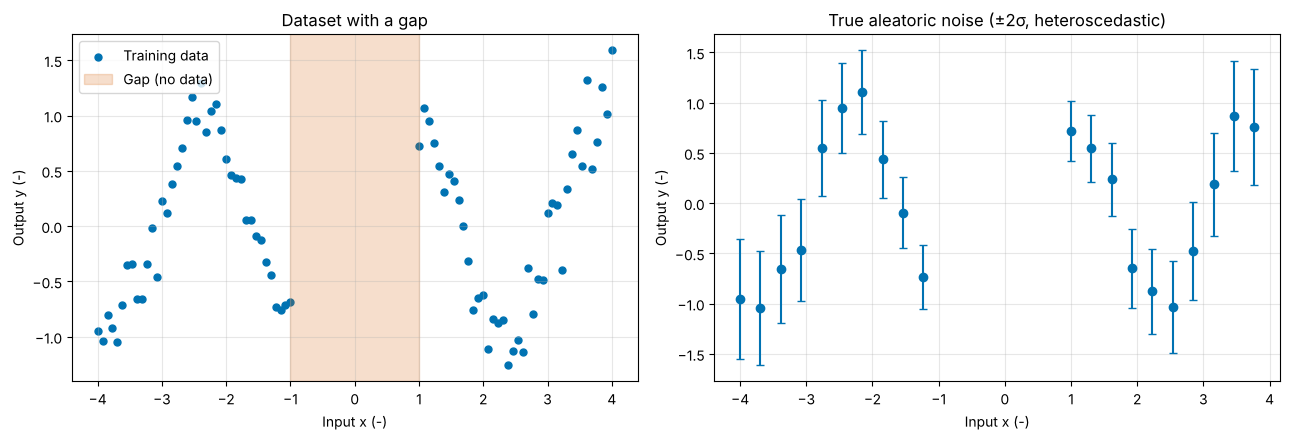

Training samples: 80; gap: (-1, 1); noise std from 0.15 to 0.30


In [3]:
def create_dataset_with_gap(seed=0):
    r = np.random.default_rng(seed)
    x_train = np.concatenate([np.linspace(-4, -1, 40), np.linspace(1, 4, 40)])
    noise_std = 0.1 + 0.05 * np.abs(x_train)                 # heteroscedastic aleatoric noise
    y_train = np.sin(2 * x_train) + r.standard_normal(len(x_train)) * noise_std
    x_test = np.linspace(-6, 6, 300)
    return x_train, y_train, x_test, noise_std

x_train, y_train, x_test, noise_std = create_dataset_with_gap()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(x_train, y_train, s=25, color=OI[4], label="Training data")
axes[0].axvspan(-1, 1, alpha=0.2, color=OI[5], label="Gap (no data)")
axes[0].set_title("Dataset with a gap"); axes[0].legend()
axes[1].errorbar(x_train[::4], y_train[::4], yerr=2 * noise_std[::4], fmt="o", color=OI[4], capsize=3)
axes[1].set_title("True aleatoric noise (±2σ, heteroscedastic)")
for ax in axes:
    ax.set_xlabel("Input x (-)"); ax.set_ylabel("Output y (-)")
plt.tight_layout(); plt.show()
print(f"Training samples: {len(x_train)}; gap: (-1, 1); noise std from {noise_std.min():.2f} to {noise_std.max():.2f}")

Final training MSE: 0.0360


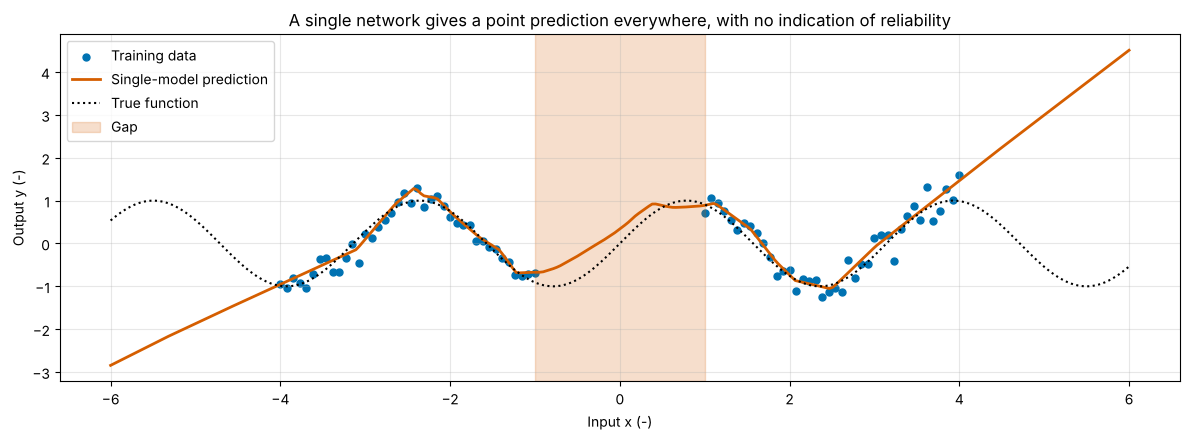

Mean |error| inside the gap: 0.310; on the training range: 0.117


In [4]:
class SimpleNN(nn.Module):
    """Point-estimate regressor (no uncertainty)."""
    def __init__(self, hidden=50):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(1, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 1))
    def forward(self, x):
        return self.net(x)

Xtr = torch.tensor(x_train, dtype=torch.float32).unsqueeze(1)
Ytr = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
Xte = torch.tensor(x_test, dtype=torch.float32).unsqueeze(1)

model = SimpleNN()
opt = torch.optim.Adam(model.parameters(), lr=0.01)
for epoch in range(1000):
    opt.zero_grad(); loss = F.mse_loss(model(Xtr), Ytr); loss.backward(); opt.step()
print(f"Final training MSE: {loss.item():.4f}")

with torch.no_grad():
    y_pred = model(Xte).squeeze().numpy()
plt.figure(figsize=(12, 4.5))
plt.scatter(x_train, y_train, s=25, color=OI[4], label="Training data")
plt.plot(x_test, y_pred, color=OI[5], lw=2, label="Single-model prediction")
plt.plot(x_test, np.sin(2 * x_test), "k:", label="True function")
plt.axvspan(-1, 1, alpha=0.2, color=OI[5], label="Gap")
plt.xlabel("Input x (-)"); plt.ylabel("Output y (-)")
plt.title("A single network gives a point prediction everywhere, with no indication of reliability")
plt.legend(); plt.tight_layout(); plt.show()
gap = (x_test > -1) & (x_test < 1)
print(f"Mean |error| inside the gap: {np.abs(y_pred[gap] - np.sin(2 * x_test[gap])).mean():.3f}; "
      f"on the training range: {np.abs(y_pred[~gap & (np.abs(x_test) <= 4)] - np.sin(2 * x_test[~gap & (np.abs(x_test) <= 4)])).mean():.3f}")

### 2.1 A heteroscedastic deep ensemble

Each of $M=5$ members predicts a mean $\mu_m(x)$ and a variance $\sigma_m^2(x)$ and is trained with the Gaussian negative log-likelihood (Lakshminarayanan et al., 2017). The law of total variance then splits the predictive variance into an aleatoric and an epistemic part.

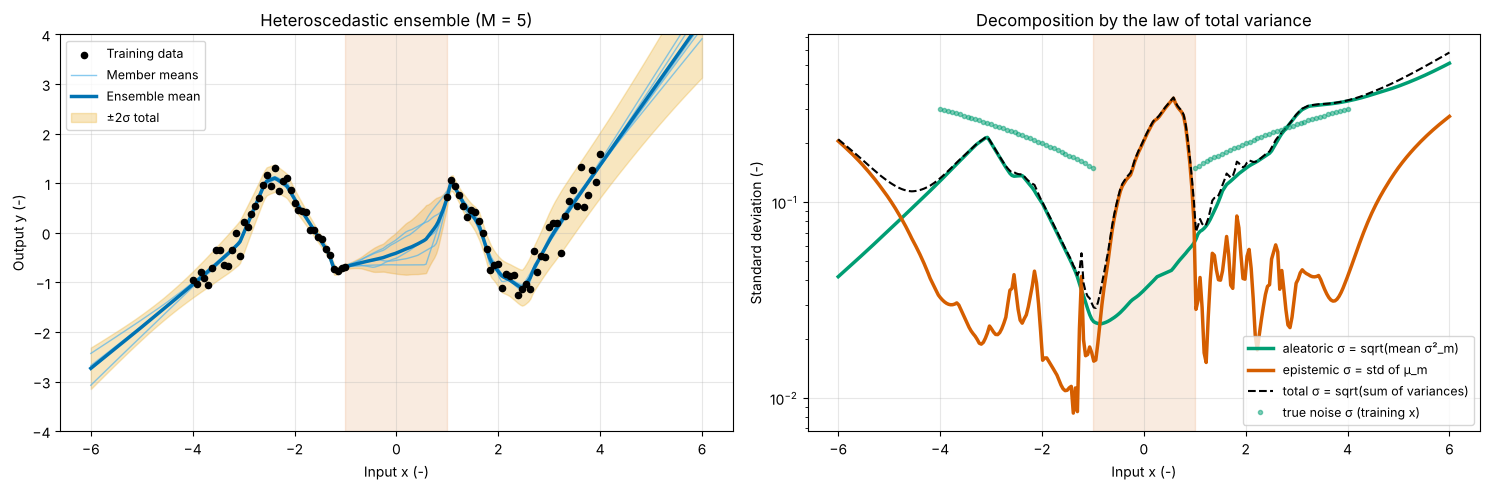

region              mean aleatoric σ  mean epistemic σ  epi/ale variance
training range                 0.185             0.034              0.03
gap (-1, 1)                    0.039             0.204             27.53
outside |x| > 4                0.292             0.147              0.25

Epistemic share of variance is 801x larger in the gap than on the training range.


In [5]:
class HeteroscedasticNN(nn.Module):
    def __init__(self, hidden=50):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(1, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU())
        self.mu = nn.Linear(hidden, 1)
        self.log_var = nn.Linear(hidden, 1)
    def forward(self, x):
        h = self.body(x)
        return self.mu(h), self.log_var(h).clamp(-10, 5)

def gaussian_nll(mu, log_var, y):
    return 0.5 * (log_var + (y - mu) ** 2 / log_var.exp()).mean()

M = 5
members = []
for m in range(M):
    torch.manual_seed(100 + m)                      # different random initialisation per member
    net = HeteroscedasticNN()
    opt = torch.optim.Adam(net.parameters(), lr=0.005)
    for epoch in range(1500):
        opt.zero_grad(); mu, lv = net(Xtr); loss = gaussian_nll(mu, lv, Ytr); loss.backward(); opt.step()
    members.append(net)

with torch.no_grad():
    outs = [net(Xte) for net in members]
mu_s = np.stack([o[0].squeeze().numpy() for o in outs])          # (M, N)
var_s = np.stack([o[1].exp().squeeze().numpy() for o in outs])   # (M, N)
total_var, ale_var, epi_var = decompose_regression(mu_s, var_s)
mean_pred = mu_s.mean(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.scatter(x_train, y_train, s=20, color="black", zorder=3, label="Training data")
for m in range(M):
    ax.plot(x_test, mu_s[m], color=OI[1], lw=1, alpha=0.7, label="Member means" if m == 0 else None)
ax.plot(x_test, mean_pred, color=OI[4], lw=2.5, label="Ensemble mean")
ax.fill_between(x_test, mean_pred - 2 * np.sqrt(total_var), mean_pred + 2 * np.sqrt(total_var),
                color=OI[0], alpha=0.25, label="±2σ total")
ax.axvspan(-1, 1, alpha=0.12, color=OI[5])
ax.set_ylim(-4, 4); ax.set_xlabel("Input x (-)"); ax.set_ylabel("Output y (-)")
ax.set_title("Heteroscedastic ensemble (M = 5)"); ax.legend(fontsize=9, loc="upper left")
ax = axes[1]
ax.plot(x_test, np.sqrt(ale_var), color=OI[2], lw=2.5, label="aleatoric σ = sqrt(mean σ²_m)")
ax.plot(x_test, np.sqrt(epi_var), color=OI[5], lw=2.5, label="epistemic σ = std of μ_m")
ax.plot(x_test, np.sqrt(total_var), "k--", lw=1.5, label="total σ = sqrt(sum of variances)")
ax.plot(x_train, noise_std, "o", color=OI[2], ms=3, alpha=0.5, label="true noise σ (training x)")
ax.axvspan(-1, 1, alpha=0.12, color=OI[5])
ax.set_yscale("log"); ax.set_xlabel("Input x (-)"); ax.set_ylabel("Standard deviation (-)")
ax.set_title("Decomposition by the law of total variance"); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

regions = {"training range": (np.abs(x_test) >= 1) & (np.abs(x_test) <= 4),
           "gap (-1, 1)": np.abs(x_test) < 1,
           "outside |x| > 4": np.abs(x_test) > 4}
print(f"{'region':18s} {'mean aleatoric σ':>17s} {'mean epistemic σ':>17s} {'epi/ale variance':>17s}")
for name, mask in regions.items():
    print(f"{name:18s} {np.sqrt(ale_var[mask].mean()):17.3f} {np.sqrt(epi_var[mask].mean()):17.3f} "
          f"{epi_var[mask].mean() / ale_var[mask].mean():17.2f}")
r_train = epi_var[regions['training range']].mean() / ale_var[regions['training range']].mean()
r_gap = epi_var[regions['gap (-1, 1)']].mean() / ale_var[regions['gap (-1, 1)']].mean()
print(f"\nEpistemic share of variance is {r_gap / r_train:.0f}x larger in the gap than on the training range.")

Observations to check against the printed numbers:
- On the training range the aleatoric σ tracks the true heteroscedastic noise, and members agree, so the epistemic part is small.
- In the gap and outside the data the members' means diverge, so the epistemic part grows. Note that the aleatoric estimate in those regions is itself an *extrapolation* by each member and is not trustworthy there.
- Five members are a coarse posterior approximation. They can agree by chance in some regions without data, so a small epistemic value is weak evidence of familiarity.

## 3. Sources of uncertainty in AV perception

### 3.1 Sensor level (mostly aleatoric)
**Camera:** photon noise in low light, motion blur, lens distortion, rain drops, dirt, glare.
**LiDAR:** range noise of a few centimetres, fewer returns from dark or wet surfaces, interference, sparse points at long range.
**Radar:** limited angular resolution, multipath reflections, ghost targets.

### 3.2 Perception level (both types)
**Aleatoric:** occlusion, truncation, genuinely ambiguous objects (bag or small animal?).
**Epistemic:** novel object types, rare scenarios (overturned truck), domain shift (new city, new weather), corner cases.

### 3.3 Combining two uncertainty estimates correctly

The scenario values below are illustrative standard deviations of a pedestrian **distance estimate** (in metres) split into aleatoric and epistemic parts. Because variances add, iso-lines of constant total uncertainty are **circles**, not diagonals.

> **Illustrative data:** values below are synthetic, chosen for teaching; they are not measurements.

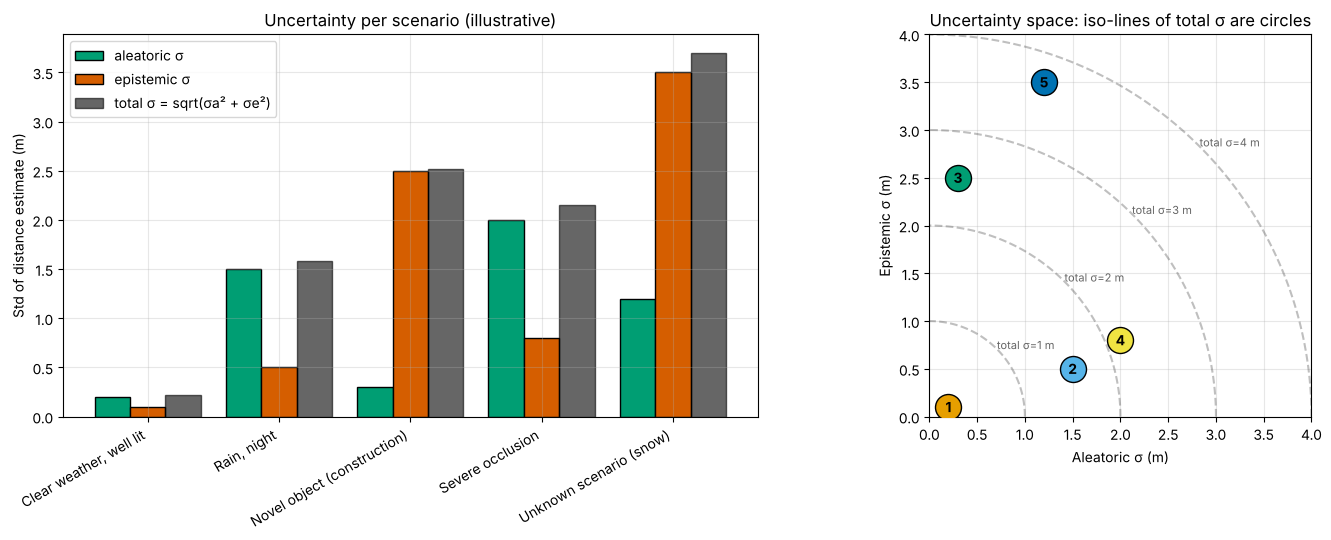

Scenarios ranked by total σ (m):
  5. Unknown scenario (snow)        total 3.70 (aleatoric 1.20, epistemic 3.50; epistemic-dominated)
  3. Novel object (construction)    total 2.52 (aleatoric 0.30, epistemic 2.50; epistemic-dominated)
  4. Severe occlusion               total 2.15 (aleatoric 2.00, epistemic 0.80; aleatoric-dominated)
  2. Rain, night                    total 1.58 (aleatoric 1.50, epistemic 0.50; aleatoric-dominated)
  1. Clear weather, well lit        total 0.22 (aleatoric 0.20, epistemic 0.10; aleatoric-dominated)

Wrong linear sum for scenario 5 would be 4.70 m instead of 3.70 m.


In [6]:
scenarios = [
    ("Clear weather, well lit",      0.20, 0.10),
    ("Rain, night",                  1.50, 0.50),
    ("Novel object (construction)",  0.30, 2.50),
    ("Severe occlusion",             2.00, 0.80),
    ("Unknown scenario (snow)",      1.20, 3.50),
]
names = [s[0] for s in scenarios]
ale = np.array([s[1] for s in scenarios]); epi = np.array([s[2] for s in scenarios])
total = np.sqrt(ale**2 + epi**2)          # variances add (law of total variance)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
x = np.arange(len(names)); w = 0.27
ax1.bar(x - w, ale, w, label="aleatoric σ", color=OI[2], edgecolor="black")
ax1.bar(x, epi, w, label="epistemic σ", color=OI[5], edgecolor="black")
ax1.bar(x + w, total, w, label="total σ = sqrt(σa² + σe²)", color=OI[7], alpha=0.6, edgecolor="black")
ax1.set_xticks(x); ax1.set_xticklabels(names, rotation=30, ha="right")
ax1.set_ylabel("Std of distance estimate (m)"); ax1.set_title("Uncertainty per scenario (illustrative)"); ax1.legend()

theta = np.linspace(0, np.pi / 2, 100)
for r in [1, 2, 3, 4]:
    ax2.plot(r * np.cos(theta), r * np.sin(theta), "k--", alpha=0.25)
    ax2.text(r * np.cos(np.pi / 4), r * np.sin(np.pi / 4), f"total σ={r} m", fontsize=8, alpha=0.6)
for i, (a, e) in enumerate(zip(ale, epi)):
    ax2.scatter(a, e, s=350, color=OI[i], edgecolor="black", zorder=3)
    ax2.annotate(str(i + 1), (a, e), ha="center", va="center", fontweight="bold")
ax2.set_xlabel("Aleatoric σ (m)"); ax2.set_ylabel("Epistemic σ (m)")
ax2.set_xlim(0, 4); ax2.set_ylim(0, 4); ax2.set_aspect("equal")
ax2.set_title("Uncertainty space: iso-lines of total σ are circles")
plt.tight_layout(); plt.show()

order = np.argsort(-total)
print("Scenarios ranked by total σ (m):")
for i in order:
    dom = "epistemic" if epi[i] > ale[i] else "aleatoric"
    print(f"  {i+1}. {names[i]:30s} total {total[i]:.2f} (aleatoric {ale[i]:.2f}, epistemic {epi[i]:.2f}; {dom}-dominated)")
print(f"\nWrong linear sum for scenario 5 would be {ale[4] + epi[4]:.2f} m instead of {total[4]:.2f} m.")

## 4. Example: pedestrian classification with posterior samples

For a classifier, aleatoric uncertainty shows up as **predicted probabilities away from 0 and 1 in every posterior sample** (expected entropy), while epistemic uncertainty shows up as **spread of the predicted probability across posterior samples** (mutual information). Below, each case is described by its mean score and by how much $S=200$ posterior samples disagree (spread on the logit scale). All uncertainty numbers are *computed* from those samples.

> **Illustrative data:** values below are synthetic, chosen for teaching; they are not measurements.

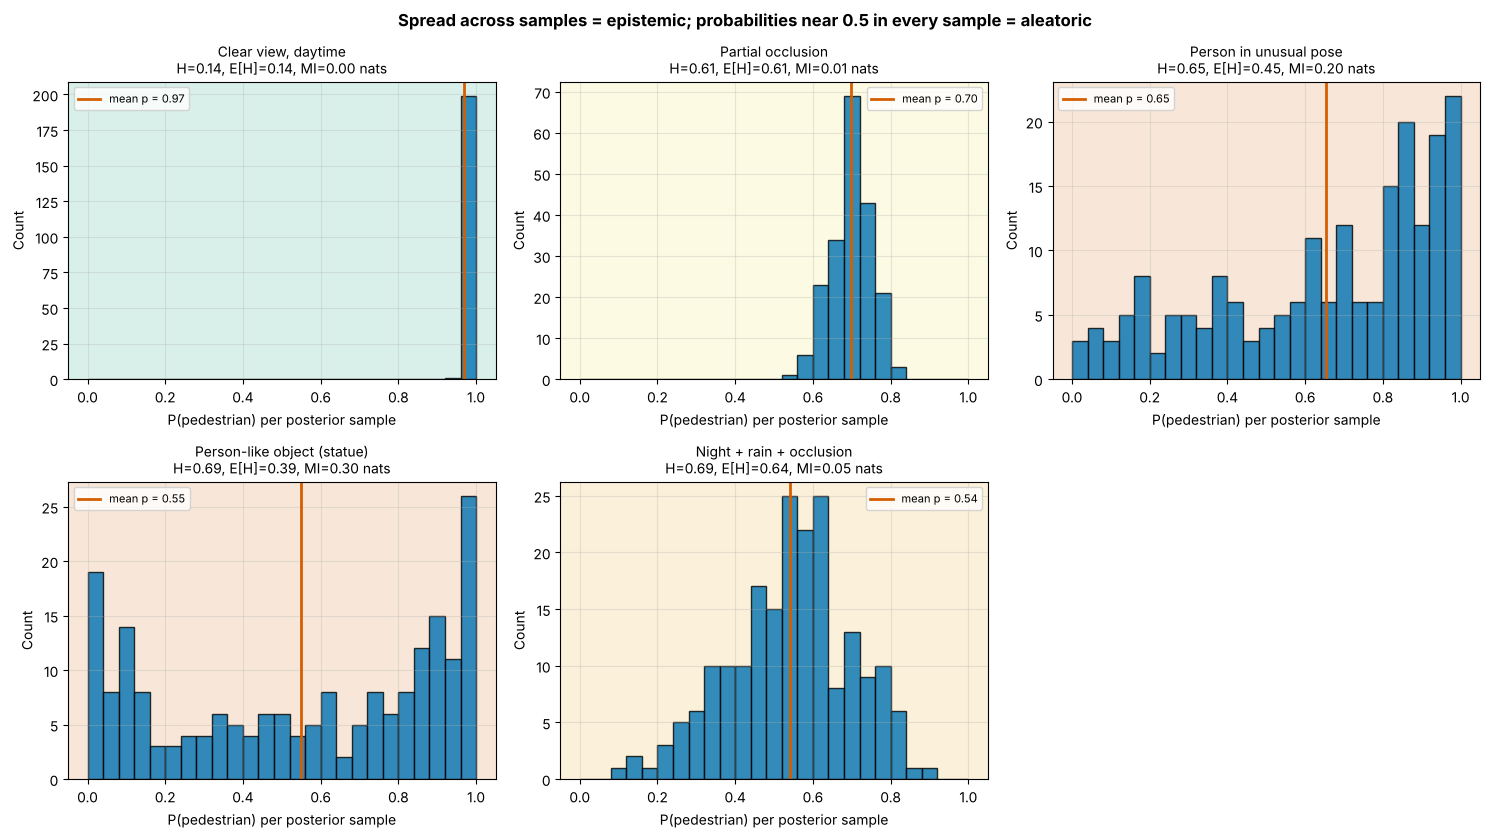

Scenario                        mean p  total  aleat.     MI  decision (illustrative rule)
Clear view, daytime               0.97   0.14    0.14   0.00  normal operation
Partial occlusion                 0.70   0.61    0.61   0.01  caution (aleatoric-dominated)
Person in unusual pose            0.65   0.65    0.45   0.20  minimal risk manoeuvre
Person-like object (statue)       0.55   0.69    0.39   0.30  minimal risk manoeuvre
Night + rain + occlusion          0.54   0.69    0.64   0.05  fallback (slow down, hand over)


In [7]:
def logit(p): return np.log(p / (1 - p))
def sigmoid(z): return 1 / (1 + np.exp(-z))

ped_cases = [   # (scenario, mean score, posterior spread on logit scale)
    ("Clear view, daytime",          0.97, 0.15),
    ("Partial occlusion",            0.70, 0.25),
    ("Person in unusual pose",       0.75, 1.80),
    ("Person-like object (statue)",  0.60, 2.50),
    ("Night + rain + occlusion",     0.55, 0.70),
]
# Illustrative thresholds (nats); the same rule is drawn as zones in Section 5.4
T_NORMAL, MI_FALLBACK, MI_MRM = 0.25, 0.05, 0.15

def decide(total, mi):
    if mi >= MI_MRM:
        return "minimal risk manoeuvre"
    if mi >= MI_FALLBACK and total >= T_NORMAL:
        return "fallback (slow down, hand over)"
    if total >= T_NORMAL:
        return "caution (aleatoric-dominated)"
    return "normal operation"

S = 200
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5)); axes = axes.ravel()
rows = []
for ax, (name, m, s) in zip(axes, ped_cases):
    p_s = sigmoid(logit(m) + s * rng.standard_normal(S))        # posterior samples of P(pedestrian)
    P = np.stack([p_s, 1 - p_s], axis=-1)[:, None, :]           # (S, 1, 2)
    t, a, e = (v[0] for v in decompose_classification(P))
    act = decide(t, e)
    rows.append((name, p_s.mean(), t, a, e, act))
    ax.hist(p_s, bins=np.linspace(0, 1, 26), color=OI[4], edgecolor="black", alpha=0.8)
    ax.axvline(p_s.mean(), color=OI[5], lw=2, label=f"mean p = {p_s.mean():.2f}")
    ax.set_facecolor(mcolors.to_rgba({"normal": OI[2], "caution": OI[3], "fallback": OI[0], "minimal": OI[5]}[act.split()[0]], 0.15))
    ax.set_title(f"{name}\nH={t:.2f}, E[H]={a:.2f}, MI={e:.2f} nats", fontsize=10)
    ax.set_xlabel("P(pedestrian) per posterior sample"); ax.set_ylabel("Count"); ax.legend(fontsize=8)
axes[-1].axis("off")
plt.suptitle("Spread across samples = epistemic; probabilities near 0.5 in every sample = aleatoric", fontweight="bold")
plt.tight_layout(); plt.show()

print(f"{'Scenario':30s} {'mean p':>7s} {'total':>6s} {'aleat.':>7s} {'MI':>6s}  decision (illustrative rule)")
for name, mp, t, a, e, act in rows:
    print(f"{name:30s} {mp:7.2f} {t:6.2f} {a:7.2f} {e:6.2f}  {act}")

## 5. Why uncertainty matters for safety standards

### 5.1 ISO 26262 (functional safety)
- Relevant parts: **Part 4** (product development at the system level, including safety validation in Clause 8), **Part 6** (software level) and **Part 8** (supporting processes such as verification, configuration management and confidence in software tools).
- ISO 26262 addresses malfunctions caused by faults. Uncertainty estimates do **not** provide hardware *diagnostic coverage* (an ISO 26262-5 metric for random hardware faults).
- The ML component still runs on hardware and software that must meet ISO 26262 for their own malfunctions.

### 5.2 ISO 21448 (SOTIF)
ISO 21448 classifies scenarios into four areas: **Area 1** known not hazardous, **Area 2** known hazardous, **Area 3** unknown hazardous, **Area 4** unknown not hazardous. The goal is to reduce Areas 2 and 3 to an acceptable residual risk.

How uncertainty helps:
- High epistemic uncertainty on recorded data can point developers towards scenarios that may belong to Area 3, i.e. it is a tool for *discovering* triggering conditions (see [04_SOTIF/03 OOD monitoring as safety measure](../04_SOTIF_ISO21448/03_ood_monitoring_as_safety_measure.ipynb)).
- At runtime it can feed a monitor that triggers degraded modes; the monitor's own detection performance must then be verified.

### 5.3 ISO/PAS 8800
Uncertainty estimation is one of the properties and measures discussed for AI systems: as a safety-related property (are the estimates calibrated?), as an architectural measure (runtime monitors), and as input to measures during operation. The author's work evaluates exactly this question for LiDAR object detection: whether uncertainty estimates identify performance insufficiencies in a SOTIF analysis (Patel & Jung, VEHITS 2026), and how evidence-theoretic (Dempster–Shafer) representations can complement probabilistic ones (Patel & Jung, 2026).

### 5.4 Uncertainty-aware decision zones

For a binary classifier the total entropy is at most $\ln 2$, so the feasible region in the (aleatoric, epistemic) plane is the triangle $\text{aleatoric} + \text{MI} \le \ln 2$. The zones below are **illustrative**: real thresholds must be derived from a risk analysis and validated (false alarms of a monitor are also hazardous, e.g. unnecessary braking).

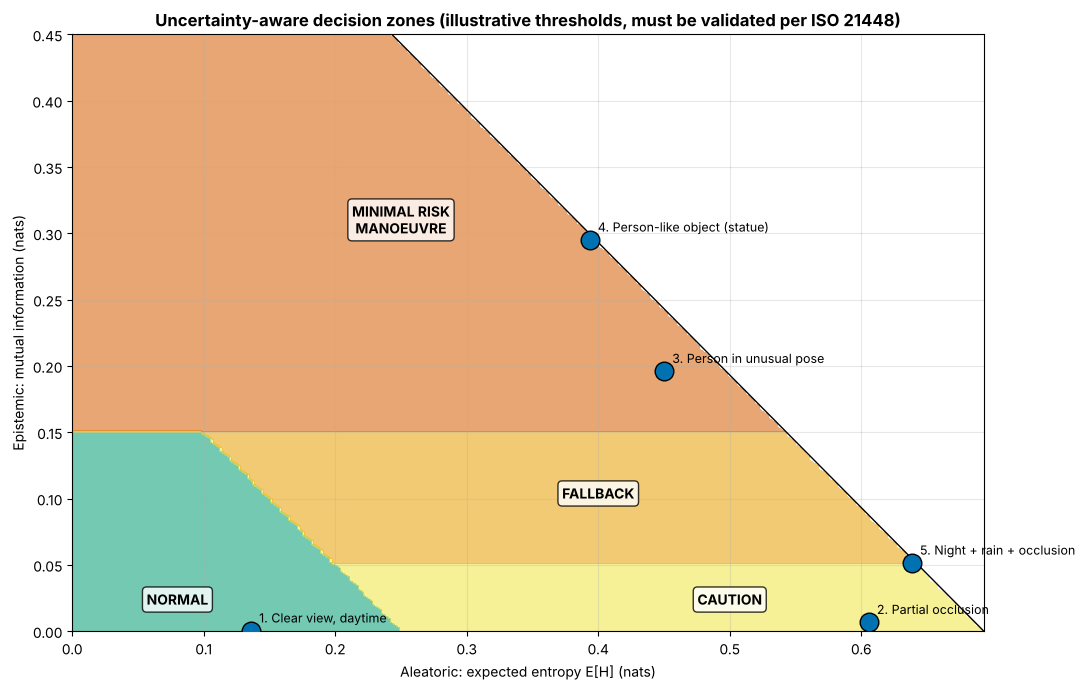

1. Clear view, daytime            aleatoric 0.14, MI 0.00 nats -> normal operation
2. Partial occlusion              aleatoric 0.61, MI 0.01 nats -> caution (aleatoric-dominated)
3. Person in unusual pose         aleatoric 0.45, MI 0.20 nats -> minimal risk manoeuvre
4. Person-like object (statue)    aleatoric 0.39, MI 0.30 nats -> minimal risk manoeuvre
5. Night + rain + occlusion       aleatoric 0.64, MI 0.05 nats -> fallback (slow down, hand over)


In [8]:
A_, E_ = np.meshgrid(np.linspace(0, np.log(2), 200), np.linspace(0, 0.45, 200))
T_ = A_ + E_
code = {"normal": 1, "caution": 2, "fallback": 3, "minimal": 4}
zones = np.vectorize(lambda t, e: code[decide(t, e).split()[0]])(T_, E_).astype(float)  # same rule as Section 4
zones[T_ > np.log(2)] = np.nan                                 # infeasible for 2 classes

fig, ax = plt.subplots(figsize=(11, 7))
cmap = mcolors.ListedColormap([OI[2], OI[3], OI[0], OI[5]])
ax.contourf(A_, E_, zones, levels=[0.5, 1.5, 2.5, 3.5, 4.5], cmap=cmap, alpha=0.55)
ax.plot([0, np.log(2)], [np.log(2), 0], "k-", lw=1)
for i, (name, mp, t, a, e, act) in enumerate(rows):
    ax.scatter(a, e, s=180, color=OI[4], edgecolor="black", zorder=4)
    ax.annotate(f"{i+1}. {name}", (a, e), xytext=(6, 6), textcoords="offset points", fontsize=9)
for (x, y, txt) in [(0.08, 0.02, "NORMAL"), (0.5, 0.02, "CAUTION"), (0.4, 0.10, "FALLBACK"), (0.25, 0.30, "MINIMAL RISK\nMANOEUVRE")]:
    ax.text(x, y, txt, fontsize=10, fontweight="bold", ha="center",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
ax.set_xlim(0, np.log(2)); ax.set_ylim(0, 0.45)
ax.set_xlabel("Aleatoric: expected entropy E[H] (nats)"); ax.set_ylabel("Epistemic: mutual information (nats)")
ax.set_title("Uncertainty-aware decision zones (illustrative thresholds, must be validated per ISO 21448)", fontweight="bold")
plt.tight_layout(); plt.show()

for i, (name, mp, t, a, e, act) in enumerate(rows):
    print(f"{i+1}. {name:30s} aleatoric {a:.2f}, MI {e:.2f} nats -> {act}")

## 6. Overview of uncertainty quantification methods

The next notebooks implement several of these.

### 6.1 Approximate Bayesian methods
- **Bayesian neural networks** with variational inference or MCMC: posterior over weights.
- **Monte Carlo dropout** (Gal & Ghahramani, 2016): dropout at test time as approximate variational inference.
- **Laplace approximation** (e.g. Daxberger et al., 2021): Gaussian posterior around a trained network.

### 6.2 Ensembles
- **Deep ensembles** (Lakshminarayanan et al., 2017): independently initialised members.
- **Snapshot and batch ensembles**: cheaper variants.

**What they capture:** both Bayesian approximations and ensembles estimate *epistemic* uncertainty via disagreement between samples. *Aleatoric* uncertainty is captured only if the likelihood models it (softmax probabilities, or a heteroscedastic variance head), as combined by Kendall & Gal (2017).

### 6.3 Single-pass methods
- **Heteroscedastic networks:** learn the aleatoric variance.
- **Deterministic uncertainty methods** such as DUQ (van Amersfoort et al., 2020): aim at epistemic/OOD uncertainty in a single pass.
- **Evidential deep learning:** predicts the parameters of a Dirichlet distribution; its epistemic estimates have been criticised (Bengs et al., 2022).

### 6.4 Post-hoc calibration and distribution-free sets
- **Temperature scaling, Platt scaling, isotonic regression**: make scores match observed frequencies ([04 Calibration](04_calibration.ipynb)).
- **Conformal prediction**: prediction sets with a finite-sample coverage guarantee under exchangeability ([05 Conformal prediction](05_conformal_prediction.ipynb)).

## Key takeaways

- Aleatoric uncertainty reflects noise and ambiguity *given the inputs*; epistemic uncertainty reflects lack of knowledge and shrinks with relevant data.
- Use one consistent decomposition: **entropy = expected entropy + mutual information** (classification) and **variance = mean variance + variance of means** (regression). Standard deviations do not add.
- Mean scores near 0.5 can hide very different situations; only the decomposition separates "ambiguous" from "unfamiliar".
- Ensembles and MC dropout estimate epistemic uncertainty through disagreement; aleatoric estimates need a likelihood that models noise.
- Uncertainty is one input to SOTIF analysis and runtime monitoring under ISO 21448 and ISO/PAS 8800. It is not diagnostic coverage in the ISO 26262 sense, and thresholds built on it must be validated.

## Self-assessment

1. What is the difference between aleatoric and epistemic uncertainty?
2. Why can aleatoric uncertainty sometimes be reduced after all?
3. An ensemble gives member probabilities 0.9, 0.1, 0.9, 0.1 for "pedestrian". Is the uncertainty mostly aleatoric or epistemic? Why?
4. Two independent error sources have σ = 3 m and σ = 4 m. What is the total σ?
5. Why must an uncertainty-based fallback trigger itself be validated?
6. Which standard covers a perception miss caused by fog without any hardware fault?

<details>
<summary>Answers</summary>

1. Aleatoric: inherent noise or ambiguity in the data given the chosen inputs; irreducible by more samples of the same kind. Epistemic: uncertainty about the model because of limited data or knowledge; reducible with more relevant data.
2. Because it is defined relative to the input representation. Better sensors, additional modalities or extra features can resolve ambiguities that are irreducible for the original inputs.
3. Mostly epistemic. Each member is fairly confident (low expected entropy), but they disagree strongly, which gives high mutual information.
4. 5 m, because variances add: sqrt(3² + 4²) = 5. Adding standard deviations would wrongly give 7 m.
5. Because both missed triggers (unsafe continuation) and false triggers (unnecessary braking, which can cause rear-end collisions) are potentially hazardous. Its detection rate and false-alarm rate per ODD slice are safety-relevant properties.
6. ISO 21448 (a functional insufficiency triggered by a condition, without a fault); for the ML-specific causes, ISO/PAS 8800 refines the analysis. ISO 26262 does not apply because no E/E malfunction occurred.
</details>

## References

- Der Kiureghian, A., Ditlevsen, O. (2009). Aleatory or epistemic? Does it matter? *Structural Safety* 31(2), 105–112. https://doi.org/10.1016/j.strusafe.2008.06.020
- Hüllermeier, E., Waegeman, W. (2021). Aleatoric and epistemic uncertainty in machine learning: an introduction to concepts and methods. *Machine Learning* 110, 457–506. https://doi.org/10.1007/s10994-021-05946-3
- Kendall, A., Gal, Y. (2017). What uncertainties do we need in Bayesian deep learning for computer vision? NeurIPS 2017. arXiv:1703.04977
- Depeweg, S. et al. (2018). Decomposition of uncertainty in Bayesian deep learning for efficient and risk-sensitive learning. ICML 2018. arXiv:1710.07283
- Gal, Y., Ghahramani, Z. (2016). Dropout as a Bayesian approximation. ICML 2016. arXiv:1506.02142
- Lakshminarayanan, B., Pritzel, A., Blundell, C. (2017). Simple and scalable predictive uncertainty estimation using deep ensembles. NeurIPS 2017. arXiv:1612.01474
- van Amersfoort, J. et al. (2020). Uncertainty estimation using a single deep deterministic neural network. ICML 2020. arXiv:2003.02037
- Bengs, V., Hüllermeier, E., Waegeman, W. (2022). Pitfalls of epistemic uncertainty quantification through loss minimisation. NeurIPS 2022. arXiv:2203.06102
- Daxberger, E. et al. (2021). Laplace Redux — effortless Bayesian deep learning. NeurIPS 2021. arXiv:2106.14806
- ISO 21448:2022; ISO 26262:2018; ISO/PAS 8800:2024.
- Patel, M., Jung, R. (2026). Uncertainty Evaluation to Support Safety of the Intended Functionality Analysis for Identifying Performance Insufficiencies in ML-Based LiDAR Object Detection. VEHITS 2026. https://doi.org/10.5220/0014967200004030
- Patel, M., Jung, R. (2026). Uncertainty Representation in a SOTIF-Related Use Case with Dempster-Shafer Theory for LiDAR Sensor-Based Object Detection. CCIS, Springer. https://doi.org/10.1007/978-3-032-23187-1_10

---
**Navigation:** ← [01 AI safety standards](01_ai_safety_standards.ipynb) · [Module index](README.md) · [03 MC dropout and deep ensembles](03_mc_dropout_and_deep_ensembles.ipynb) →

### Further practice

**Try this:** change the posterior spread of the cases in Section 4 and watch how the decision changes; add a sixth ensemble member in Section 2.1 and compare the epistemic estimate in the gap.

The author's companion repository [AI-Perception-Safety-Workshop](https://github.com/milinpatel07/AI-Perception-Safety-Workshop) has further exercises.